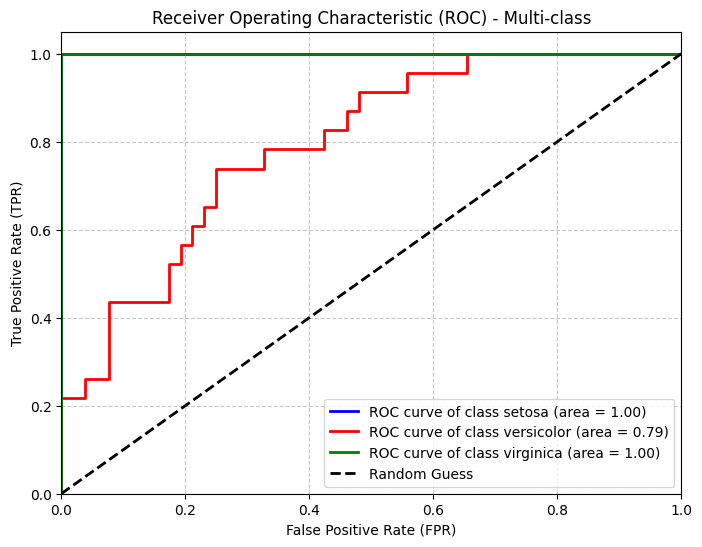

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Binarize the output for multi-class ROC analysis
y_bin = label_binarize(y, classes=[0, 1, 2])
n_classes = y_bin.shape[1]

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_bin, test_size=0.5, random_state=42)

# Learn to predict each class against the other using SVC
classifier = OneVsRestClassifier(
    SVC(kernel='linear', probability=True, random_state=42)
)
y_score = classifier.fit(X_train, y_train).decision_function(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(8, 6))
colors = ['blue', 'red', 'green']
for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f'ROC curve of class {iris.target_names[i]} (area = {roc_auc[i]:0.2f})'
    )

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) - Multi-class')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

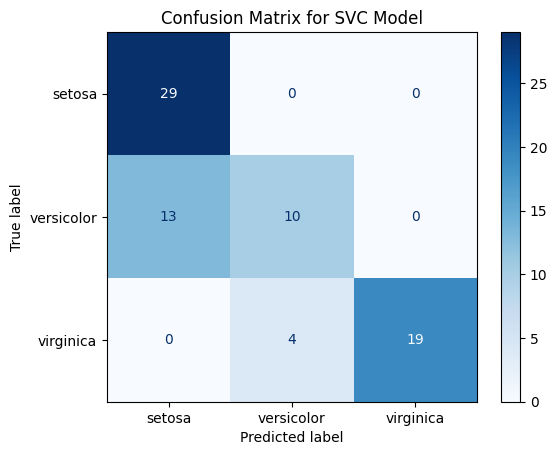

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Binarize target classes
y_bin = label_binarize(y, classes=[0, 1, 2])

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_bin, test_size=0.5, random_state=42)

# 3. Train SVC model
classifier = OneVsRestClassifier(
    SVC(kernel='linear', probability=True, random_state=42)
)
classifier.fit(X_train, y_train)

# 4. Get true labels and predicted labels
y_test_labels = np.argmax(y_test, axis=1)
y_pred_bin = classifier.predict(X_test)
y_pred_labels = np.argmax(y_pred_bin, axis=1)

# 5. Compute and plot confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for SVC Model')
plt.show()

 ID3 Algorithm (Decision Tree with Entropy) Results 
Accuracy for ID3: 0.9867

Classification Report for ID3:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        29
  versicolor       0.96      1.00      0.98        23
   virginica       1.00      0.96      0.98        23

    accuracy                           0.99        75
   macro avg       0.99      0.99      0.99        75
weighted avg       0.99      0.99      0.99        75



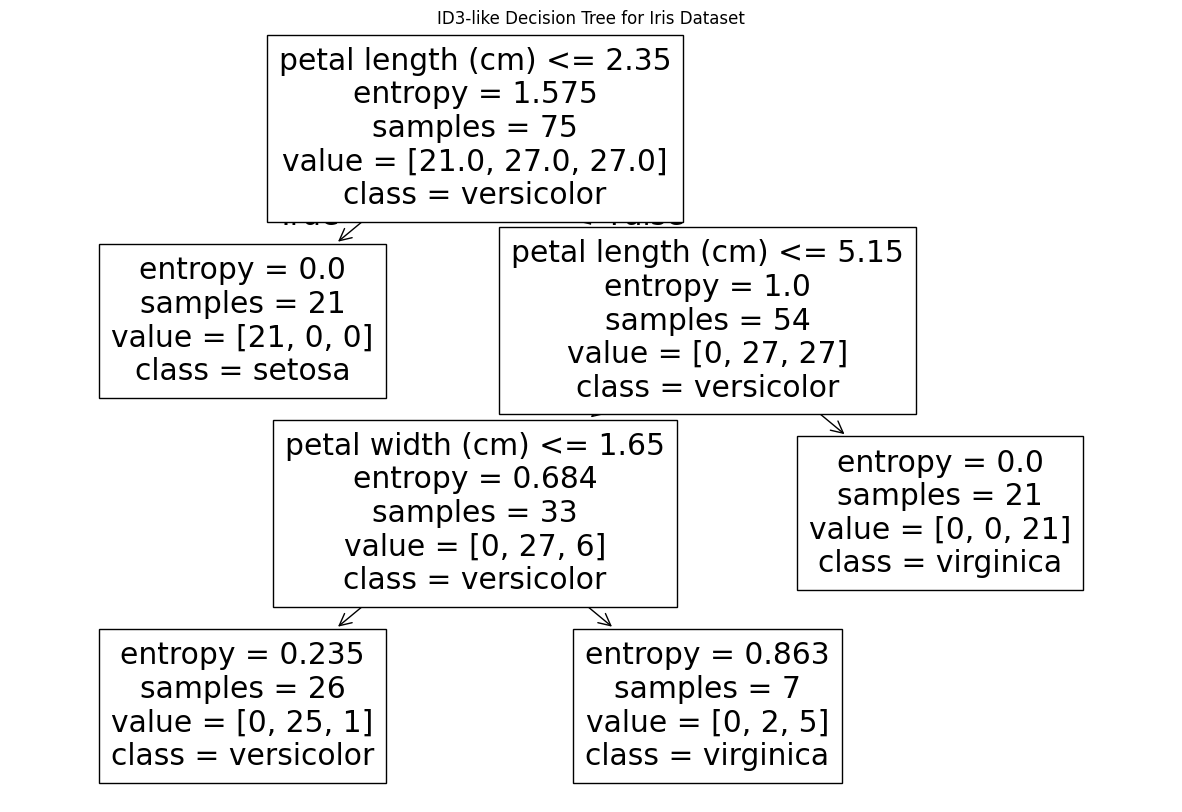

In [6]:
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the Iris dataset
iris = datasets.load_iris()
X_clf = iris.data
y_clf = iris.target

# 2. Split dataset into train and test sets using standard 1D targets (not binarized)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.5, random_state=42
)

# 3. Initialize the Decision Tree Classifier with entropy criterion
id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=3)

# 4. Train the model using the preprocessed Iris classification data
id3_model.fit(X_train_clf, y_train_clf)

# 5. Make predictions on the test set
y_pred_id3 = id3_model.predict(X_test_clf)

# 6. Evaluate the ID3-like model
accuracy_id3 = accuracy_score(y_test_clf, y_pred_id3)
print(" ID3 Algorithm (Decision Tree with Entropy) Results ")
print(f"Accuracy for ID3: {accuracy_id3:.4f}")

print("\nClassification Report for ID3:")
print(classification_report(y_test_clf, y_pred_id3, target_names=iris.target_names))

# 7. Visualize the Decision Tree
plt.figure(figsize=(15, 10))
tree.plot_tree(id3_model, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=False)
plt.title('ID3-like Decision Tree for Iris Dataset')
plt.show()

### Understanding the ROC Curve from the Confusion Matrix

An **ROC (Receiver Operating Characteristic) curve** and a **Confusion Matrix** are closely related; the points plotted on an ROC curve are calculated directly from confusion matrices evaluated at different classification thresholds.

#### 1. The Core Connection
For any binary classification task, a single **Confusion Matrix** is generated using a specific threshold (e.g., $0.5$):

| | Predicted Negative | Predicted Positive |
|---|---|---|
| **Actual Negative** | True Negative (TN) | False Positive (FP) |
| **Actual Positive** | False Negative (FN) | True Positive (TP) |

From this matrix, we calculate the two metrics plotted on the ROC curve:
*   **True Positive Rate (TPR) / Recall** (Y-axis):  
    $$\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
*   **False Positive Rate (FPR)** (X-axis):  
    $$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

#### 2. How the Confusion Matrix Maps to the ROC Curve
*   **One Confusion Matrix = One Point**: A single confusion matrix represents a single classification threshold, corresponding to exactly **one point** on the ROC curve.
*   **Changing the Thresholds**: An ROC curve is constructed by starting at a high decision threshold (where everything is predicted as negative: $\text{TPR}=0, \text{FPR}=0$ at the bottom-left point $(0,0)$) and gradually lowering it until everything is predicted as positive ($\text{TPR}=1, \text{FPR}=1$ at the top-right point $(1,1)$). At each step, a new confusion matrix is implicitly built, a new $(\text{FPR}, \text{TPR})$ pair is calculated, and a new point is drawn on the graph.

#### 3. Understanding the Multi-Class Case (Iris Dataset)
In your multi-class Iris classifier, we used a **One-vs-Rest (OvR)** strategy.
*   For **Class 0 (Setosa)**, the model separates Setosa (Positive) from non-Setosa (Negative). Because Setosa is linearly separable, its confusion matrix has $0$ false positives and $0$ false negatives. This leads to a perfect $(\text{FPR}=0, \text{TPR}=1)$ point at almost all thresholds, resulting in a perfect **AUC of 1.00**.
*   For **Class 1 (Versicolor)**, the confusion matrix shows $13$ actual Versicolor samples were misclassified as Setosa. This higher rate of false negatives drags the **TPR** down and results in a lower overall **AUC of 0.79**.